In [39]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from GraphST import GraphST
import matplotlib.pyplot as plt
import numpy as np
import anndata
import argparse
import sklearn

# Set environment variables
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

In [40]:
# # for loading DLPFC12 data·
# def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC/', section_id='151507'):
#     # 151507, ..., 151676 12 in total
#     ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5',
#                         load_images=True)
#     ad.var_names_make_unique()
#
#     gt_dir = os.path.join(root_dir, section_id, 'gt')
#     gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
#     ad.obs['original_clusters'] = gt_df.loc[:, 6]
#     keep_bcs = ad.obs.dropna().index
#     ad = ad[keep_bcs].copy()
#     ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
#     # print(ad.obs)
#     return ad

In [41]:
# def Cal_Spatial_Net(adata, rad_cutoff=None, k_cutoff=None, model='Radius', verbose=True):
#     """\
#     Construct the spatial neighbor networks.
#
#     Parameters
#     ----------
#     adata
#         AnnData object of scanpy package.
#     rad_cutoff
#         radius cutoff when model='Radius'
#     k_cutoff
#         The number of nearest neighbors when model='KNN'
#     model
#         The network construction model. When model=='Radius', the spot is connected to spots whose distance is less than rad_cutoff. When model=='KNN', the spot is connected to its first k_cutoff nearest neighbors.
#
#     Returns
#     -------
#     The spatial networks are saved in adata.uns['Spatial_Net']
#     """
#
#     assert (model in ['Radius', 'KNN'])
#     if verbose:
#         print('------Calculating spatial graph...')
#     coor = pd.DataFrame(adata.obsm['spatial'])
#     coor.index = adata.obs.index
#     #     coor.columns = ['imagerow', 'imagecol']
#
#     if model == 'Radius':
#         nbrs = sklearn.neighbors.NearestNeighbors(radius=rad_cutoff).fit(coor)
#         distances, indices = nbrs.radius_neighbors(coor, return_distance=True)
#         KNN_list = []
#         for it in range(indices.shape[0]):
#             KNN_list.append(pd.DataFrame(zip([it] * indices[it].shape[0], indices[it], distances[it])))
#
#     if model == 'KNN':
#         nbrs = sklearn.neighbors.NearestNeighbors(n_neighbors=k_cutoff + 1).fit(coor)
#         distances, indices = nbrs.kneighbors(coor)
#         KNN_list = []
#         for it in range(indices.shape[0]):
#             KNN_list.append(pd.DataFrame(zip([it] * indices.shape[1], indices[it, :], distances[it, :])))
#
#     KNN_df = pd.concat(KNN_list)
#     KNN_df.columns = ['Cell1', 'Cell2', 'Distance']
#
#     Spatial_Net = KNN_df.copy()
#     Spatial_Net = Spatial_Net.loc[Spatial_Net['Distance'] > 0,]
#     id_cell_trans = dict(zip(range(coor.shape[0]), np.array(coor.index), ))
#     Spatial_Net['Cell1'] = Spatial_Net['Cell1'].map(id_cell_trans)
#     Spatial_Net['Cell2'] = Spatial_Net['Cell2'].map(id_cell_trans)
#     if verbose:
#         print('The graph contains %d edges, %d cells.' % (Spatial_Net.shape[0], adata.n_obs))
#         print('%.4f neighbors per cell on average.' % (Spatial_Net.shape[0] / adata.n_obs))
#
#     adata.uns['Spatial_Net'] = Spatial_Net

In [42]:
# dirs = r"C:\Code\Data\DLPFC"
#
# # lists=[[151507,151508],[151508,151509],[151509,151510],[151669,151670],[151670,151671],[151671,151672],[151673,151674],[151674,151675],[151675,151676]]
# lists = [[151669, 151670],[151670, 151671],[151671, 151672],[151673, 151674],[151674, 151675],[151675, 151676]]
# out_dirs = "C:\Code\Data\DLPFC/"
#
# for sample_name in lists:
#     # IDX=np.arange(0,2)
#     IDX = np.arange(0, len(sample_name))
#     VF = []
#     MAT = []
#     flags = str(sample_name[IDX[0]])
#     for i in np.arange(1, len(IDX)):
#         flags = flags + '-' + str(sample_name[IDX[i]])
#     flags = flags + "_"
#     for k in np.arange(len(IDX)):
#         adata = load_DLPFC(root_dir=dirs, section_id=str(sample_name[k]))
#         adata.var_names_make_unique()
#
#         sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=5000)
#         sc.pp.normalize_total(adata, target_sum=1e4)
#         sc.pp.log1p(adata)
#
#         adata.obs['batch'] = str(sample_name[IDX[k]])
#         cells = [str(sample_name[IDX[k]]) + '-' + i for i in adata.obs_names]
#         mat1 = pd.DataFrame(adata.X.toarray(), columns=adata.var_names, index=cells)
#         coord1 = pd.DataFrame(adata.obsm['spatial'], columns=['x', 'y'], index=cells)
#         meta1 = adata.obs[['original_clusters', 'batch']]
#         meta1.columns = ['celltype', 'batch']
#         meta1.index = cells
#         meta1.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[k]]) + "_label-1.txt")
#         coord1.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[k]]) + "_positions-1.txt")
#         MAT.append(mat1)
#         VF = np.union1d(VF, adata.var_names[adata.var['highly_variable']])
#
#     for i in np.arange(len(IDX)):
#         mat = MAT[i]
#         mat = mat.loc[:, VF]
#         mat.to_csv(out_dirs + "gtt_input_scanpy/" + flags + str(sample_name[IDX[i]]) + "_features-1.txt")

In [43]:
dirs=r'C:\Code\Data\DLPFC/'
# 151507,151508,151509,151510,151669,151670,151671,151672,151673,151674,151675,151676
# 设置参数
sample_name = np.array([151507, 151508, 151509, 151510, 151669, 151670, 151671, 151672, 151673, 151674, 151675, 151676])
IDX = [8, 9, 10, 11]  # 选择要处理的样本索引
samples = sample_name[IDX]
SEP = ','
net_cate = '_KNN_'
knn = 6

# 模型参数
P_WALK = knn
WALK_LEN = 1
N_WALK_LEN = knn
NUM_NEG = knn

# 生成文件名
feat_file = []
meta_file = []
coord_file = []
flags = ''
flags1 = str(samples[0])

for i in range(1, len(samples)):
    flags1 = flags1 + '-' + str(samples[i])

for i in range(len(samples)):
    feat_file.append(dirs + "gtt_input_scanpy/" + flags1 + '_' + str(samples[i]) + "_features-1.txt")
    meta_file.append(dirs + "gtt_input_scanpy/" + flags1 + '_' + str(samples[i]) + "_label-1.txt")
    coord_file.append(dirs + "gtt_input_scanpy/" + flags1 + '_' + str(samples[i]) + "_positions-1.txt")
    flags = flags + '_' + str(samples[i])

# 加载数据
feat = pd.read_csv(feat_file[0], header=0, index_col=0)
meta = pd.read_csv(meta_file[0], header=0, index_col=0)
coord = pd.read_csv(coord_file[0], header=0, index_col=0)
paste_coord = pd.read_csv(dirs + "methods/" + "paste_new_coord" + flags + ".csv", header=0, index_col=0)

for i in np.arange(1, len(samples)):
    feat = pd.concat((feat, pd.read_csv(feat_file[i], header=0, index_col=0)))
    meta = pd.concat((meta, pd.read_csv(meta_file[i], header=0, index_col=0)))
    coord = pd.concat((coord, pd.read_csv(coord_file[i], header=0, index_col=0)))

# 准备AnnData对象
meta = meta.loc[feat.index, :]
coord = coord.loc[feat.index, :]
adata = anndata.AnnData(feat)
adata.obs['celltype'] = meta.loc[:, 'celltype']
adata.obs['batch'] = meta.loc[:, 'batch']
adata.obsm['spatial'] = paste_coord.loc[adata.obs_names, ['x', 'y', 'z']].values

adata.var_names_make_unique()

# 定义并运行模型
model = GraphST.GraphST(adata, device=device)
adata = model.train()

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\scanpy\preprocessing\_highly_variable_genes.py:75: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(


图构建完成: 同一切片内选择11个邻居，从3个不同切片各选择1个邻居
Begin to train ST data...


100%|██████████| 600/600 [01:19<00:00,  7.55it/s]


Optimization finished for ST data!


In [44]:
# 保存AnnData对象
os.makedirs(dirs + "gtt_output", exist_ok=True)  # 确保输出目录存在
output_filename = dirs + "gtt_output/GraphST_ann_" + "_".join(map(str, samples)) + ".h5ad"
adata.write(output_filename)
print(f"已保存AnnData对象到 {output_filename}")

已保存AnnData对象到 C:\Code\Data\DLPFC/gtt_output/GraphST_ann_151673_151674_151675_151676.h5ad


In [45]:
from GraphST.utils import clustering
num_cluster = 7
clustering(adata, n_clusters=num_cluster, radius=50, method='mclust', key='emb')

fitting ...
  |======================================================================| 100%


In [46]:
from sklearn.metrics.cluster import adjusted_rand_score as ari_score
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
proj_list = ['151673', '151674', '151675', '151676']
# 确保标签字段正确设置
# 将mclust标签值减1，使范围变为0-6
sub_adata = adata[~pd.isnull(adata.obs['celltype'])]
sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)
samples = list(sub_adata.obs['batch_name'].unique())

# 创建新列，避免修改原始数据
sub_adata.obs['mclust_adjusted'] = sub_adata.obs['mclust'].astype(int) - 1

ARI = ari_score(sub_adata.obs['celltype'], sub_adata.obs['mclust_adjusted'])
print(f"总体 ARI: {ARI:.4f}")

for name in samples:
    sub_sample = sub_adata[sub_adata.obs['batch_name'] == name]
    ARI = ari_score(sub_sample.obs['celltype'], sub_sample.obs['mclust_adjusted'])
    print(f"{name} ARI: {ARI:.4f}")

C:\Users\CLEARLOVE\AppData\Local\Temp\ipykernel_8672\1071308960.py:7: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)


总体 ARI: 0.3785
151673 ARI: 0.3759
151674 ARI: 0.3844
151675 ARI: 0.3910
151676 ARI: 0.3819


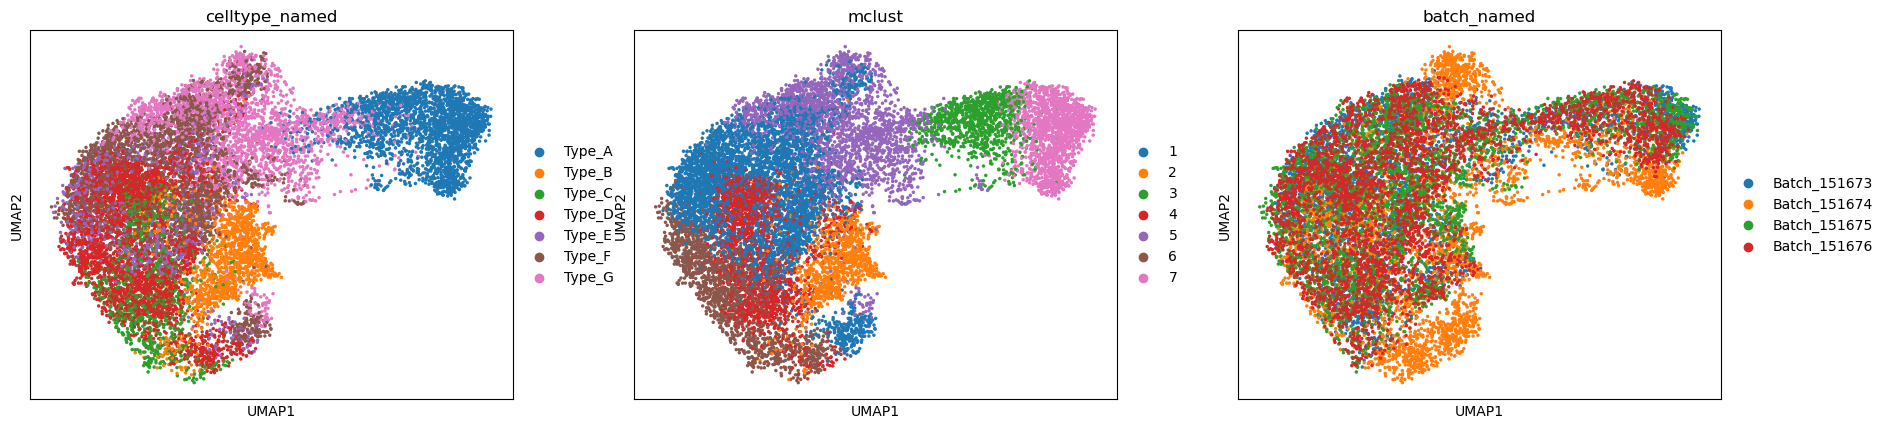

In [47]:
celltype_names = {
    '0': 'Type_A', '1': 'Type_B', '2': 'Type_C',
    '3': 'Type_D', '4': 'Type_E', '5': 'Type_F', '6': 'Type_G'
}

batch_names = {str(b): f'Batch_{b}' for b in adata.obs['batch'].unique()}

# 应用映射
adata.obs['celltype_named'] = adata.obs['celltype'].astype(str).map(celltype_names)
adata.obs['batch_named'] = adata.obs['batch'].astype(str).map(batch_names)

sc.pp.neighbors(adata, use_rep='emb', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['celltype_named', 'mclust', 'batch_named'], show=True, size=25, save=False)

In [48]:
# 计算ARI
sub_adata = adata[~pd.isnull(adata.obs['celltype'])]
sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)
ARI = ari_score(sub_adata.obs['celltype'], sub_adata.obs['mclust'])
print(f"total ARI:{ARI}")

# 计算每个batch的ARI
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    batch_ARI = ari_score(sub_adata_tmp.obs['celltype'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{batch_ARI}")

C:\Users\CLEARLOVE\AppData\Local\Temp\ipykernel_8672\1081511300.py:3: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  sub_adata.obs['batch_name'] = sub_adata.obs['batch'].astype(str)


total ARI:0.37845655235696857
151673 ARI:0.37590728020282255
151674 ARI:0.3844437272190748
151675 ARI:0.39095401114405515
151676 ARI:0.3819053210602665


In [49]:
# 计算NMI
from STG3Net import Metrics
NMI = Metrics.compute_NMI(sub_adata, 'celltype', 'mclust')
print(f"total NMI:{NMI}")
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    NMI = Metrics.compute_NMI(sub_adata_tmp, 'celltype', 'mclust')
    print(f"{name} NMI:{NMI}")


total NMI:0.556378840105434
151673 NMI:0.5849602856052988
151674 NMI:0.5534878744440522
151675 NMI:0.5659651457488347
151676 NMI:0.5667543308804518


In [50]:
# 计算HOM
HOM = Metrics.compute_HOM(sub_adata, 'celltype', 'mclust')
print(f"total HOM:{HOM}")
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    HOM = Metrics.compute_HOM(sub_adata_tmp, 'celltype', 'mclust')
    print(f"{name} HOM:{HOM}")

total HOM:0.5484180229903953
151673 HOM:0.5786718921911199
151674 HOM:0.5499864846469423
151675 HOM:0.5527904526521252
151676 HOM:0.5565652945313287


In [51]:
# 计算COM
COM = Metrics.compute_COM(sub_adata, 'celltype', 'mclust')
print(f"total COM:{COM}")
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    COM = Metrics.compute_COM(sub_adata_tmp, 'celltype', 'mclust')
    print(f"{name} COM:{COM}")

total COM:0.5645741794303727
151673 COM:0.591386851736951
151674 COM:0.557034131816241
151675 COM:0.5797831578558543
151676 COM:0.5773233854319365


In [52]:
CHAOS = Metrics.compute_CHAOS(sub_adata, 'mclust')
print(f"total CHAOS:{CHAOS}")
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    CHAOS = Metrics.compute_CHAOS(sub_adata_tmp, 'mclust')
    print(f"{name} CHAOS:{CHAOS}")

total CHAOS:0.06262309024971258
151673 CHAOS:0.062301098396887196
151674 CHAOS:0.06236325729499405
151675 CHAOS:0.06190347076972444
151676 CHAOS:0.06509705317536107


In [53]:
PAS = Metrics.compute_PAS(sub_adata, 'mclust')
print(f"total PAS:{PAS}")
for name in sub_adata.obs['batch_name'].unique():
    sub_adata_tmp = sub_adata[sub_adata.obs['batch_name'] == name]
    PAS = Metrics.compute_PAS(sub_adata_tmp, 'mclust')
    print(f"{name} PAS:{PAS}")

total PAS:0.16330829179245945
151673 PAS:0.09609526446967599
151674 PAS:0.10096286107290234
151675 PAS:0.11020751542344363
151676 PAS:0.10434275721364034


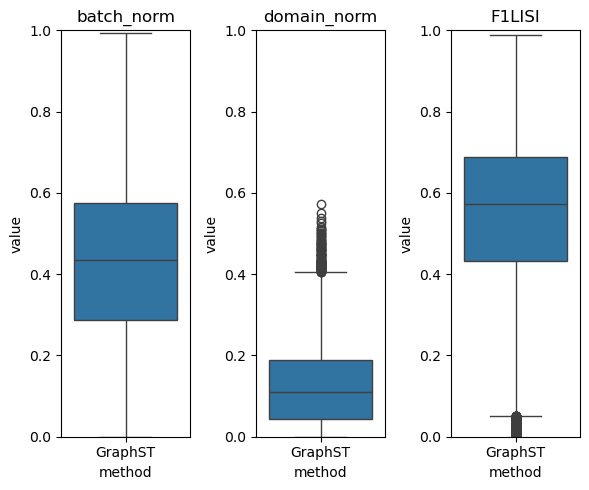

In [54]:
import harmonypy as hm
from joblib import Parallel, delayed
import numpy as np

def compute_lisi_parallel(embeddings, metadata, label_colnames, n_jobs=-1):
    """Parallelized LISI computation"""
    # Split data into chunks
    n_samples = embeddings.shape[0]
    chunk_size = max(1000, n_samples // (n_jobs if n_jobs > 0 else 1))
    chunks = [(embeddings[i:i+chunk_size], metadata.iloc[i:i+chunk_size])
              for i in range(0, n_samples, chunk_size)]

    # Compute in parallel
    results = Parallel(n_jobs=n_jobs)(
        delayed(hm.compute_lisi)(chunk_emb, chunk_meta, label_colnames)
        for chunk_emb, chunk_meta in chunks
    )

    return np.concatenate(results)

def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key, n_jobs=-1):
    num_domains = len(Tmp_adata.obs[PD_key].unique()) - 1
    num_batchs = len(Tmp_adata.obs[BT_key].unique()) - 1

    # Use parallel computation
    LISI_batch_norm = compute_lisi_parallel(
        Tmp_adata.obsm[LT_key],
        Tmp_adata.obs[[BT_key]],
        [BT_key],
        n_jobs=n_jobs
    )[:, 0]

    LISI_domain_norm = compute_lisi_parallel(
        Tmp_adata.obsm[LT_key],
        Tmp_adata.obs[[PD_key]],
        [PD_key],
        n_jobs=n_jobs
    )[:, 0]

    norm_batch = (LISI_batch_norm - 1) / num_batchs
    norm_domain = (LISI_domain_norm - 1) / num_domains
    LISI = 2 * (1 - norm_domain) * norm_batch / (1 - norm_domain + norm_batch)

    return LISI, norm_batch, norm_domain

# 使用GraphST中的变量名和嵌入表示
LISI, norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'emb', 'batch_name', 'celltype')

import seaborn as sns
import matplotlib.pyplot as plt

df_batch_norm = pd.DataFrame({
    'method': 'GraphST',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'GraphST',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'GraphST',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()
plt.show()

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


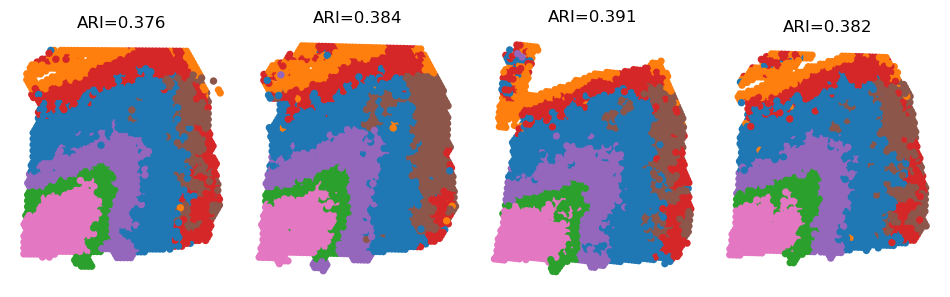

In [55]:
sample_names = sub_adata.obs['batch_name'].unique()

Batch_list = []
for section_id in sample_names:
    Batch_list.append(sub_adata[sub_adata.obs['batch_name'] == section_id])

spot_size = 300
title_size = 12
ARI_list = []
for bb in range(len(sample_names)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['celltype'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, len(sample_names), figsize=(3*len(sample_names), 5),
                       gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(sample_names)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                         legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                         spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()